# Oasis Infobyte Data Science Internship
## TASK 3: Car Price Prediction with Machine Learning
**Author:** Kunal Nevage  
**Domain:** Machine Learning & Predictive Analytics  
**Tech Stack:** Python, Pandas, NumPy, Scikit-Learn, Matplotlib, Seaborn, Jupyter Notebook  
**Dataset:** Vehicle Dataset from CarDekho (Kaggle)

---

### Project Overview & Objectives
The major objective of this project is to develop an end-to-end Machine Learning regression solution to predict the selling price of used cars based on multi-dimensional vehicle attributes, including:
- **Brand / Make** (e.g., Maruti, Hyundai, BMW, Toyota, Honda)
- **Vehicle Age** (calculated from the manufacturing year)
- **Odometer Mileage** (`km_driven` and derived annual usage `km_per_year`)
- **Fuel Type** (Petrol, Diesel, CNG, LPG, Electric)
- **Transmission Mechanism** (Manual vs. Automatic)
- **Seller Type** (Individual vs. Dealer vs. Trustmark Dealer)
- **Ownership History** (First Owner, Second Owner, etc.)

---

### Deliverables Checklist
- [x] **Download a suitable dataset:** CarDekho Vehicle Dataset (4,340 entries)
- [x] **Data cleaning:** Null value audit, duplicate removal (763 duplicates purged), categorical string formatting & casing standardization
- [x] **Feature engineering:** Derived `car_age` from `year`; extracted and standardized `brand` from car name; created `km_per_year`
- [x] **EDA:** Price distribution (raw & log), price vs. fuel type box plots, price vs. car age scatter plot with regression trend, transmission comparisons, top brands valuation
- [x] **Categorical Encoding:** One-Hot Encoding for nominal features with rare-class consolidation
- [x] **Feature Correlation Heatmap:** Correlation matrix with annotations
- [x] **Train/Test Split:** 80/20 split with reproducibility seed
- [x] **Train 4 Regression Models:** Linear Regression, Ridge Regression, Random Forest Regressor, Gradient Boosting Regressor
- [x] **Model Evaluation:** MAE, RMSE, and $R^2$ metrics across both Train and Test partitions
- [x] **Feature Importance Chart:** In-depth ranking and interpretation of the best-performing model's decision drivers
- [x] **Model Inference & Deployment Prototype:** End-to-end price estimation function demonstrated on real-world car profiles


In [1]:
# 1. Imports and Global Configuration
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn modules
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Aesthetics and Matplotlib styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Create persistence directories
os.makedirs('plots', exist_ok=True)
os.makedirs('models', exist_ok=True)

print("Environment configured successfully. Ready for data science workflow.")


Environment configured successfully. Ready for data science workflow.


---
## Step 1: Dataset Sourcing & Ingestion
We load the publicly available **CarDekho Vehicle Dataset** (`car_details.csv`). Let's examine the first few records, the schema dimensions, and summary statistics.


In [2]:
# Load raw dataset
df_raw = pd.read_csv('car_details.csv')

print(f"Dataset Dimensions: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns\n")
print("First 5 records:")
display(df_raw.head())

print("\nDataset Information:")
df_raw.info()

print("\nNumerical Feature Statistics:")
display(df_raw.describe().T)


Dataset Dimensions: 4340 rows, 8 columns

First 5 records:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 515.2 KB

Numerical Feature Statistics:


,count,mean,std,min,25%,50%,75%,max
year,4340.0,2013.090783,4.215344,1992.0,2011.00,2014.0,2016.0,2020.0
selling_price,4340.0,504127.311751,578548.736139,20000.0,208749.75,350000.0,600000.0,8900000.0
km_driven,4340.0,66215.777419,46644.102194,1.0,35000.00,60000.0,90000.0,806599.0


---
## Step 2: Data Cleaning
In this phase, we:
1. **Audit Missing/Null Values**: Check if any imputation is required.
2. **Identify & Remove Duplicates**: Car listings frequently contain redundant crawler duplicate entries.
3. **Address Inconsistent Categorical Values**: Handle leading/trailing whitespaces, casing differences (e.g., `'Petrol'` vs `'petrol'`), and verify unique categories across all categorical columns.


In [3]:
# 2.1 Audit Missing Values
null_counts = df_raw.isnull().sum()
print("Null Values Audit:")
print(null_counts)

# 2.2 Duplicate Rows Handling
num_duplicates = df_raw.duplicated().sum()
print(f"\nDuplicate rows found: {num_duplicates} ({num_duplicates / len(df_raw) * 100:.2f}%)")

# Drop duplicate rows
df_cleaned = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Shape after removing duplicates: {df_cleaned.shape}")

# 2.3 Address Inconsistent Categorical Values
categorical_cols = ['fuel', 'seller_type', 'transmission', 'owner']

for col in categorical_cols:
    # Strip whitespace and normalize to title case
    df_cleaned[col] = df_cleaned[col].astype(str).str.strip().str.title()

print("\nSanitized Unique Values in Categorical Features:")
for col in categorical_cols:
    print(f"  {col:<15}: {df_cleaned[col].unique().tolist()}")


Null Values Audit:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Duplicate rows found: 763 (17.58%)
Shape after removing duplicates: (3577, 8)

Sanitized Unique Values in Categorical Features:
  fuel           : ['Petrol', 'Diesel', 'Cng', 'Lpg', 'Electric']
  seller_type    : ['Individual', 'Dealer', 'Trustmark Dealer']
  transmission   : ['Manual', 'Automatic']
  owner          : ['First Owner', 'Second Owner', 'Fourth & Above Owner', 'Third Owner', 'Test Drive Car']


---
## Step 3: Feature Engineering
Raw data fields can be transformed to uncover significantly more predictive signal for regression:
1. **`car_age`**: Calculated as $\text{Reference Year (2020)} - \text{year}$. Vehicle depreciation is strongly non-linear with respect to age.
2. **`brand`**: Extracted from the `name` column (the first token represents the automotive manufacturer). We standardize brand names (e.g. `'Land Rover'`, `'BMW'`, `'MG'`, `'Opel'`).
3. **`km_per_year`**: Annual usage intensity calculated as $\frac{\text{km\_driven}}{\text{car\_age} + 1}$. A 5-year-old car with 100,000 km experienced much harder annual usage than a 15-year-old car with the same distance.


In [4]:
# 3.1 Calculate Car Age (Reference Year = 2020 when dataset was collected)
REFERENCE_YEAR = 2020
df_cleaned['car_age'] = REFERENCE_YEAR - df_cleaned['year']
df_cleaned['car_age'] = df_cleaned['car_age'].clip(lower=0)

# 3.2 Extract and Standardize Brand from Car Name
def extract_brand(name):
    parts = str(name).strip().split()
    if not parts:
        return "Unknown"
    first = parts[0].title()
    if first == 'Land':
        return 'Land Rover'
    elif first.lower() == 'opelcorsa':
        return 'Opel'
    elif first.lower() in ['bmw', 'mg']:
        return first.upper()
    return first

df_cleaned['brand'] = df_cleaned['name'].apply(extract_brand)

# 3.3 Annual Usage Metric: km_per_year
df_cleaned['km_per_year'] = (df_cleaned['km_driven'] / (df_cleaned['car_age'] + 1)).round(1)

print(f"Total Unique Brands Discovered: {df_cleaned['brand'].nunique()}")
print("\nTop 10 Brands by Market Listing Volume:")
print(df_cleaned['brand'].value_counts().head(10))

print("\nSample of Engineered Features:")
display(df_cleaned[['name', 'brand', 'year', 'car_age', 'km_driven', 'km_per_year', 'selling_price']].head())


Total Unique Brands Discovered: 29

Top 10 Brands by Market Listing Volume:
brand
Maruti        1072
Hyundai        637
Mahindra       328
Tata           308
Ford           220
Honda          216
Toyota         170
Chevrolet      151
Renault        110
Volkswagen      93
Name: count, dtype: int64

Sample of Engineered Features:


,name,brand,year,car_age,km_driven,km_per_year,selling_price
0,Maruti 800 AC,Maruti,2007,13,70000,5000.0,60000
1,Maruti Wagon R LXI Minor,Maruti,2007,13,50000,3571.4,135000
2,Hyundai Verna 1.6 SX,Hyundai,2012,8,100000,11111.1,600000
3,Datsun RediGO T Option,Datsun,2017,3,46000,11500.0,250000
4,Honda Amaze VX i-DTEC,Honda,2014,6,141000,20142.9,450000


---
## Step 4: Exploratory Data Analysis (EDA)
Here we explore key underlying relationships between vehicle attributes and selling price:
- **Distribution of Selling Prices:** Assessing target skewness and kurtosis.
- **Selling Price vs. Fuel Type:** Analyzing market valuations across Diesel, Petrol, CNG, LPG, and Electric.
- **Selling Price vs. Car Age:** Evaluating vehicle depreciation curves and outlier behavior.
- **Selling Price vs. Transmission & Seller Type:** Understanding premium valuation drivers.
- **Top 10 Car Brands by Average Valuation:** Comparing luxury badges vs. economy market leaders.


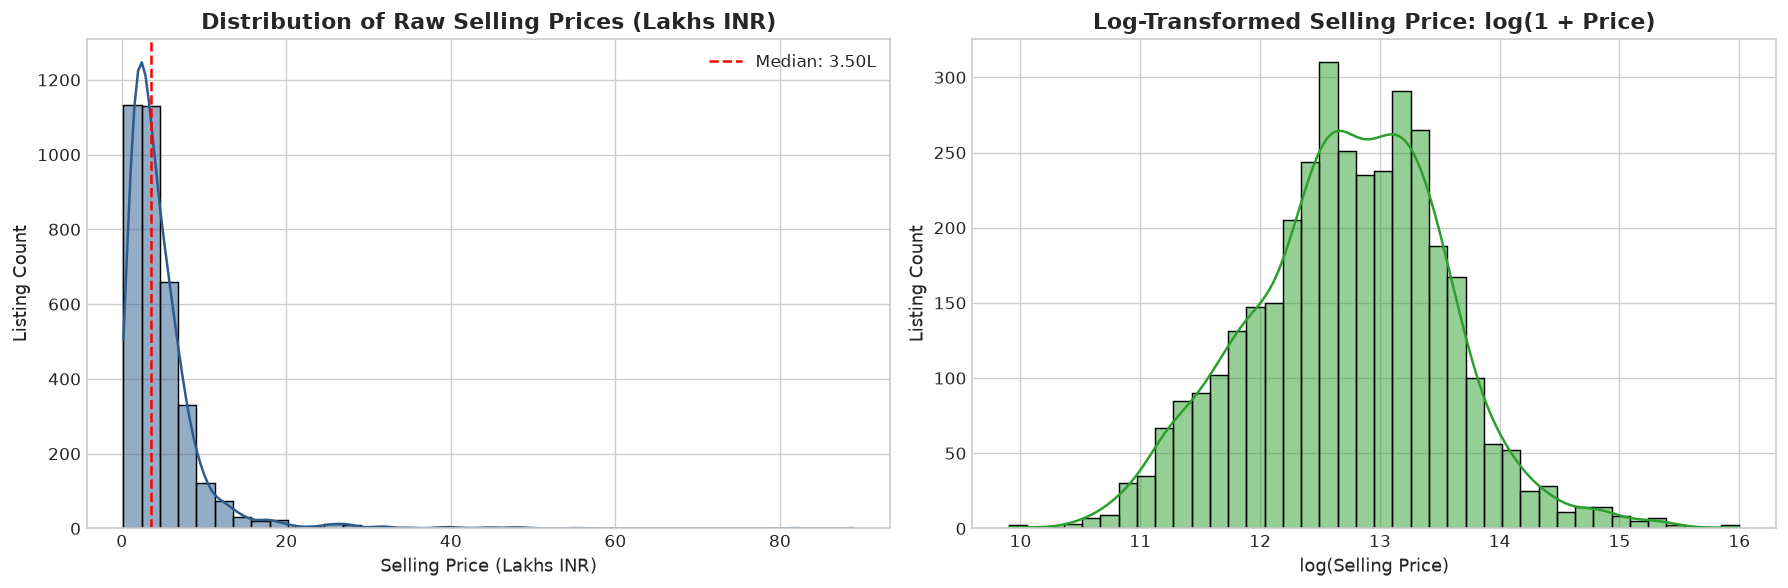

Selling Price Skewness: 5.45 (Heavy right skew)
Log(Price) Skewness:    -0.02 (Near-Gaussian distribution)


In [5]:
# 4.1 Target Variable Analysis: Distribution of Selling Prices
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Raw Selling Price in Lakhs (1 Lakh = 100,000 INR)
sns.histplot(df_cleaned['selling_price'] / 1e5, kde=True, color='#2b5c8f', ax=axes[0], bins=40)
axes[0].set_title('Distribution of Raw Selling Prices (Lakhs INR)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Selling Price (Lakhs INR)', fontsize=11)
axes[0].set_ylabel('Listing Count', fontsize=11)
axes[0].axvline(df_cleaned['selling_price'].median() / 1e5, color='red', linestyle='--', label=f'Median: {df_cleaned["selling_price"].median()/1e5:.2f}L')
axes[0].legend()

# Log-Transformed Selling Price
sns.histplot(np.log1p(df_cleaned['selling_price']), kde=True, color='#2ca02c', ax=axes[1], bins=40)
axes[1].set_title('Log-Transformed Selling Price: log(1 + Price)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('log(Selling Price)', fontsize=11)
axes[1].set_ylabel('Listing Count', fontsize=11)

plt.tight_layout()
plt.savefig('plots/eda_price_distribution.png')
plt.show()

print(f"Selling Price Skewness: {df_cleaned['selling_price'].skew():.2f} (Heavy right skew)")
print(f"Log(Price) Skewness:    {np.log1p(df_cleaned['selling_price']).skew():.2f} (Near-Gaussian distribution)")


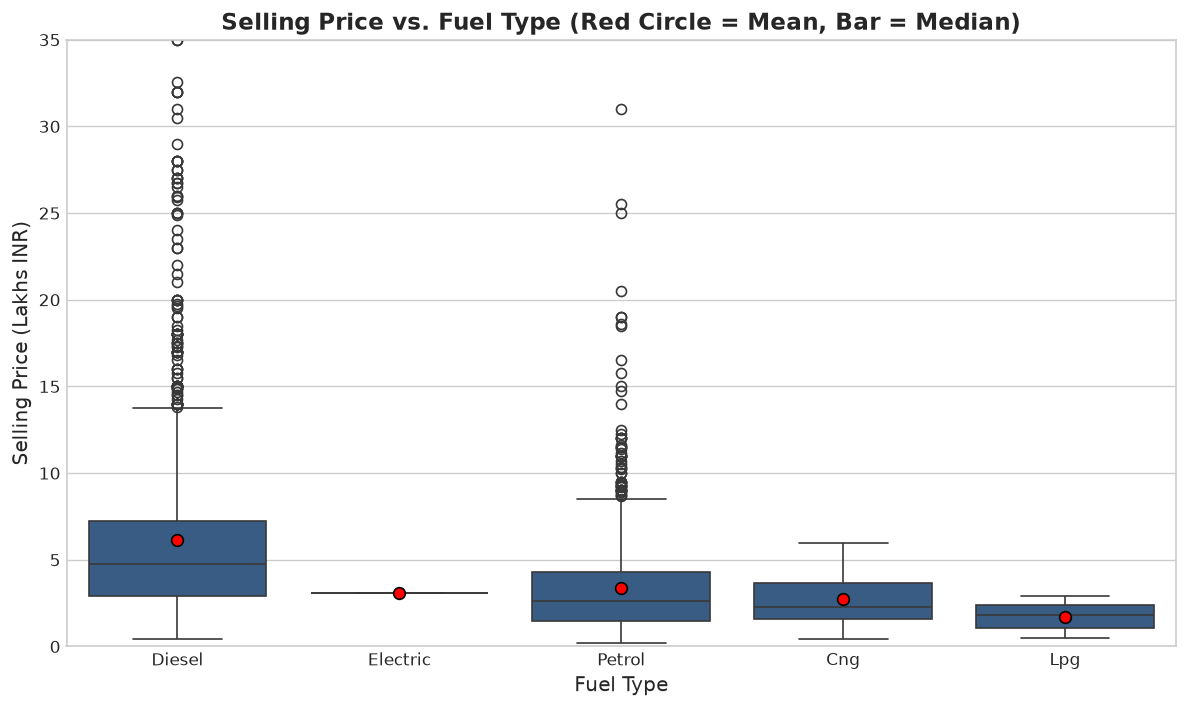

Median Selling Price by Fuel Type (Lakhs INR):


fuel
Cng         2.30
Diesel      4.75
Electric    3.10
Lpg         1.80
Petrol      2.60
Name: selling_price, dtype: float64

In [6]:
# 4.2 Selling Price vs. Fuel Type Box Plots
plt.figure(figsize=(10, 6))
fuel_order = df_cleaned.groupby('fuel')['selling_price'].median().sort_values(ascending=False).index

sns.boxplot(
    data=df_cleaned,
    x='fuel',
    y=df_cleaned['selling_price'] / 1e5,
    order=fuel_order,
    color='#2b5c8f',
    showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "red", "markeredgecolor": "black", "markersize": "7"}
)

plt.title('Selling Price vs. Fuel Type (Red Circle = Mean, Bar = Median)', fontsize=14, fontweight='bold')
plt.xlabel('Fuel Type', fontsize=12)
plt.ylabel('Selling Price (Lakhs INR)', fontsize=12)
plt.ylim(0, 35)
plt.tight_layout()
plt.savefig('plots/eda_price_vs_fuel.png')
plt.show()

print("Median Selling Price by Fuel Type (Lakhs INR):")
display((df_cleaned.groupby('fuel')['selling_price'].median() / 1e5).round(2))


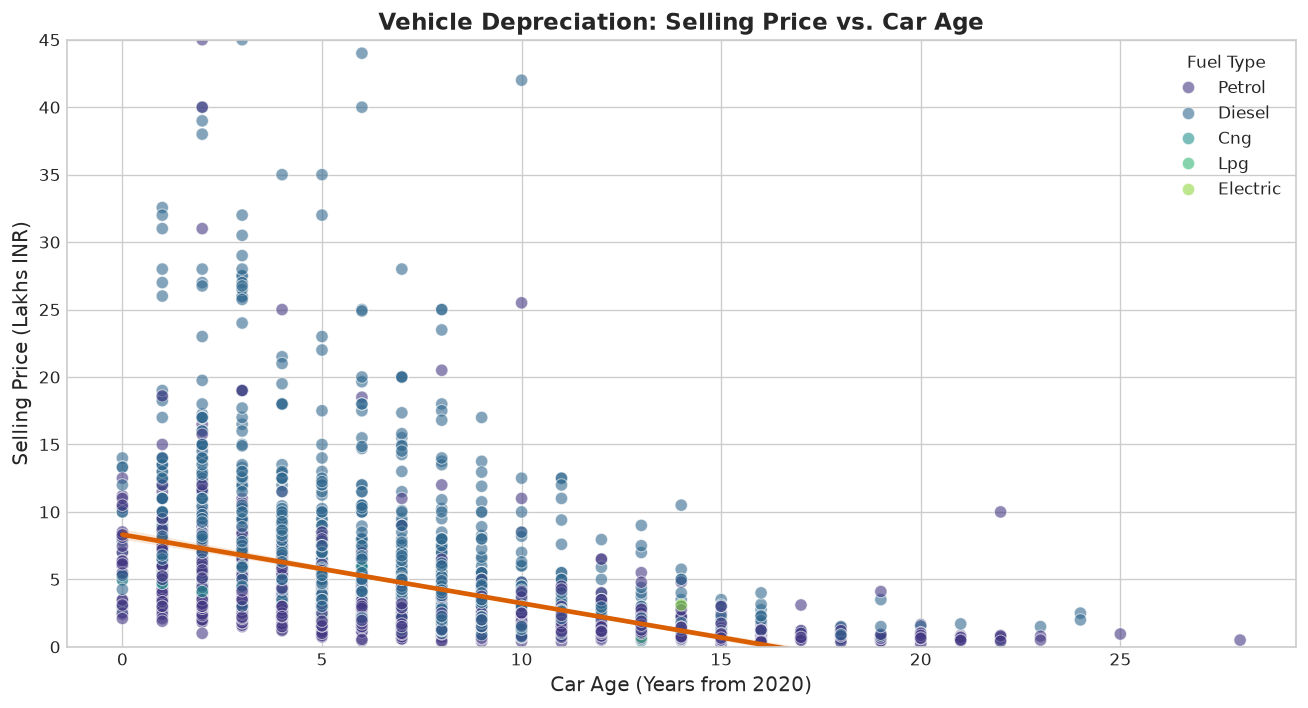

In [7]:
# 4.3 Selling Price vs. Car Age Scatter Plot with Depreciation Curve
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=df_cleaned,
    x='car_age',
    y=df_cleaned['selling_price'] / 1e5,
    hue='fuel',
    palette='viridis',
    alpha=0.6,
    s=55
)

# Overlay non-linear / linear trend line
sns.regplot(
    data=df_cleaned,
    x='car_age',
    y=df_cleaned['selling_price'] / 1e5,
    scatter=False,
    color='#d95f02',
    line_kws={'linewidth': 2.8, 'label': 'Depreciation Trendline'}
)

plt.title('Vehicle Depreciation: Selling Price vs. Car Age', fontsize=14, fontweight='bold')
plt.xlabel('Car Age (Years from 2020)', fontsize=12)
plt.ylabel('Selling Price (Lakhs INR)', fontsize=12)
plt.ylim(0, 45)
plt.legend(title='Fuel Type', loc='upper right')
plt.tight_layout()
plt.savefig('plots/eda_price_vs_age.png')
plt.show()


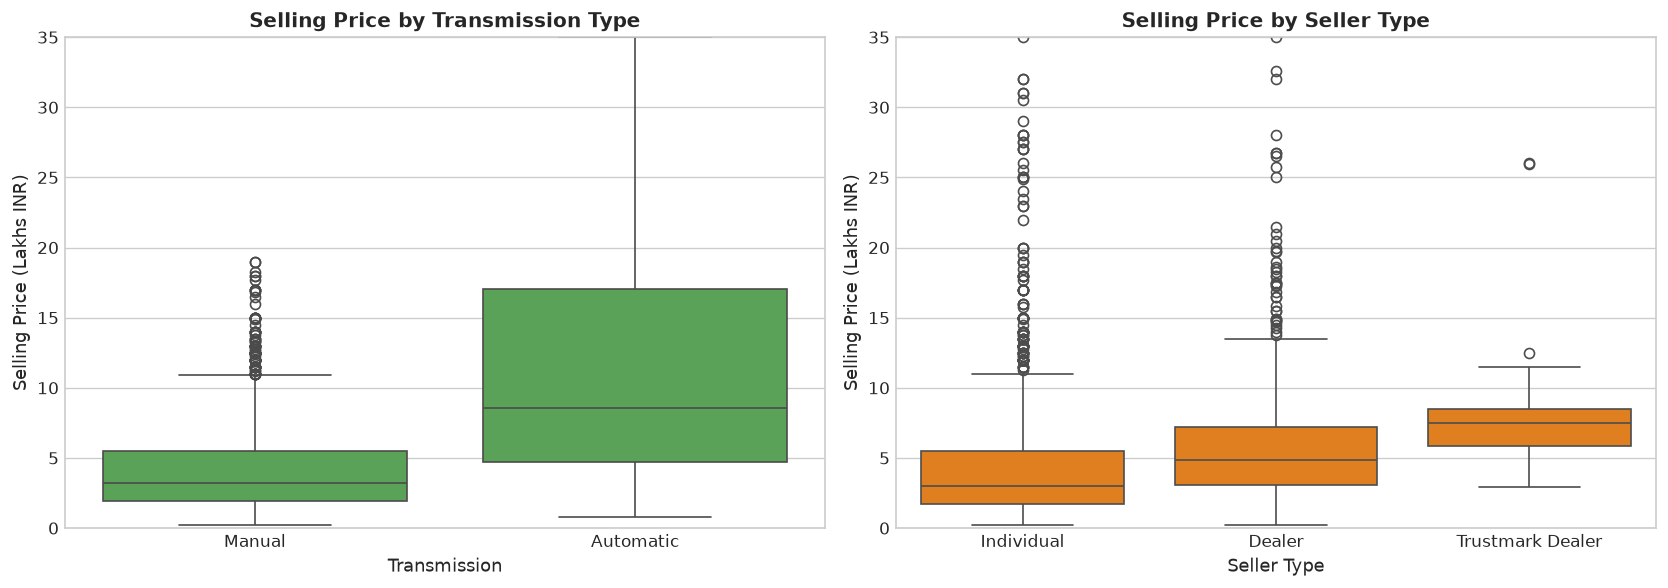

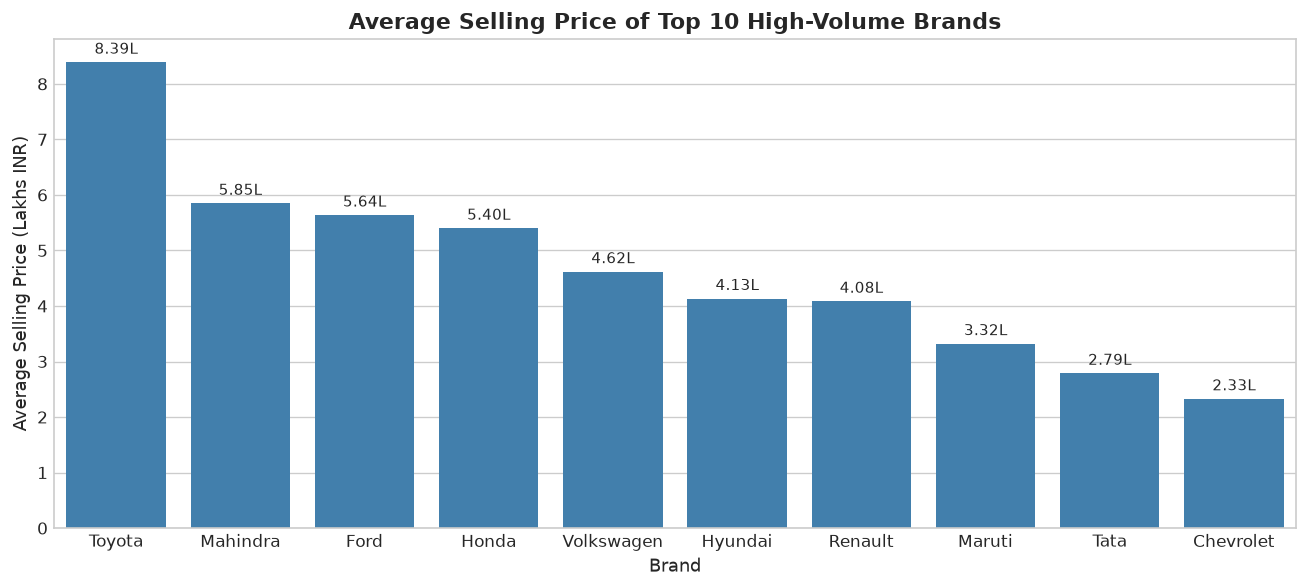

In [8]:
# 4.4 Selling Price vs. Transmission & Seller Type
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_cleaned, x='transmission', y=df_cleaned['selling_price'] / 1e5, color='#4daf4a', ax=axes[0])
axes[0].set_title('Selling Price by Transmission Type', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Transmission', fontsize=11)
axes[0].set_ylabel('Selling Price (Lakhs INR)', fontsize=11)
axes[0].set_ylim(0, 35)

sns.boxplot(data=df_cleaned, x='seller_type', y=df_cleaned['selling_price'] / 1e5, color='#ff7f00', ax=axes[1])
axes[1].set_title('Selling Price by Seller Type', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Seller Type', fontsize=11)
axes[1].set_ylabel('Selling Price (Lakhs INR)', fontsize=11)
axes[1].set_ylim(0, 35)

plt.tight_layout()
plt.savefig('plots/eda_transmission_seller.png')
plt.show()

# 4.5 Top 10 High-Volume Brands Average Price
top10_brands = df_cleaned['brand'].value_counts().head(10).index
df_top10 = df_cleaned[df_cleaned['brand'].isin(top10_brands)]
brand_stats = df_top10.groupby('brand')['selling_price'].mean().div(1e5).sort_values(ascending=False).reset_index()

plt.figure(figsize=(11, 5))
bar = sns.barplot(data=brand_stats, x='brand', y='selling_price', color='#3182bd')
plt.title('Average Selling Price of Top 10 High-Volume Brands', fontsize=13, fontweight='bold')
plt.xlabel('Brand', fontsize=11)
plt.ylabel('Average Selling Price (Lakhs INR)', fontsize=11)
for p in bar.patches:
    bar.annotate(f"{p.get_height():.2f}L", (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.savefig('plots/eda_top_brands_avg_price.png')
plt.show()


---
## Step 5: Feature Correlation Heatmap
We compute Pearson correlation coefficients between numerical metrics (`car_age`, `km_driven`, `km_per_year`, `selling_price`) along with key binary vehicle indicators (`is_automatic`, `is_diesel`, `is_individual`, `is_first_owner`).


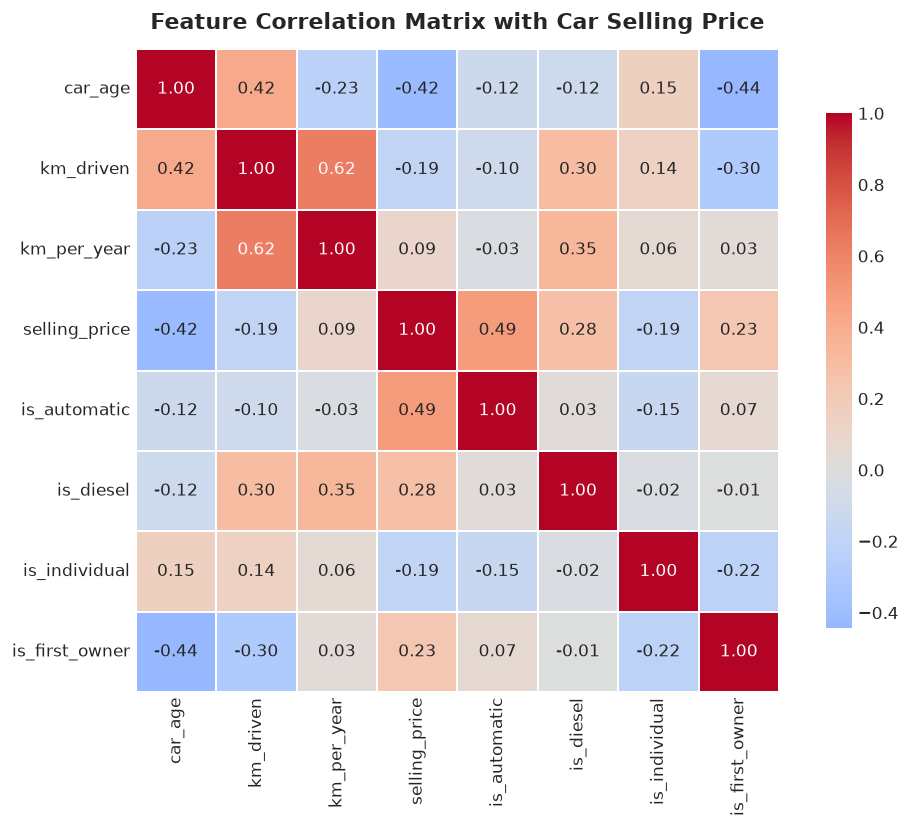

Correlation with Selling Price:
selling_price     1.000000
is_automatic      0.486269
is_diesel         0.276873
is_first_owner    0.229482
km_per_year       0.093890
km_driven        -0.187359
is_individual    -0.187640
car_age          -0.424260
Name: selling_price, dtype: float64


In [9]:
# Construct numerical correlation frame
df_corr = df_cleaned[['car_age', 'km_driven', 'km_per_year', 'selling_price']].copy()
df_corr['is_automatic'] = (df_cleaned['transmission'] == 'Automatic').astype(int)
df_corr['is_diesel'] = (df_cleaned['fuel'] == 'Diesel').astype(int)
df_corr['is_individual'] = (df_cleaned['seller_type'] == 'Individual').astype(int)
df_corr['is_first_owner'] = (df_cleaned['owner'] == 'First Owner').astype(int)

plt.figure(figsize=(9, 7))
corr_matrix = df_corr.corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=1.0,
    cbar_kws={'shrink': 0.8}
)

plt.title('Feature Correlation Matrix with Car Selling Price', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('plots/eda_correlation_heatmap.png')
plt.show()

print("Correlation with Selling Price:")
print(corr_matrix['selling_price'].sort_values(ascending=False))


---
## Step 6: Categorical Encoding & Train/Test Split
To prepare our dataset for regression algorithms:
1. **Consolidate Low-Frequency Brands:** Brands with fewer than 10 listings are grouped into an `'Other'` category to prevent sparse dummy vectors and overfitting on isolated samples.
2. **One-Hot Encoding:** Applied to `brand`, `fuel`, `seller_type`, `transmission`, and `owner` with `drop_first=True` to avoid multicollinearity (the dummy variable trap).
3. **Train/Test Partition:** 80% Training partition for fitting models, 20% holdout Testing partition for unbiased evaluation with `random_state=42`.


In [10]:
df_proc = df_cleaned.copy()

# Group rare brands (< 10 listings) into 'Other'
brand_counts = df_proc['brand'].value_counts()
frequent_brands = brand_counts[brand_counts >= 10].index
df_proc['brand'] = df_proc['brand'].apply(lambda b: b if b in frequent_brands else 'Other')

print(f"Frequent brands retained: {len(frequent_brands)} | Low-frequency brands mapped to 'Other'")

# Define predictors and target
feature_cols = ['brand', 'car_age', 'km_driven', 'km_per_year', 'fuel', 'seller_type', 'transmission', 'owner']
X_raw = df_proc[feature_cols]
y = df_proc['selling_price']

# One-Hot Encoding
X = pd.get_dummies(X_raw, drop_first=True)
feature_names = list(X.columns)

print(f"Feature matrix dimensions: {X.shape[0]} rows x {X.shape[1]} features")

# Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training observations: {X_train.shape[0]} ({X_train.shape[0]/len(X):.0%})")
print(f"Testing observations:  {X_test.shape[0]} ({X_test.shape[0]/len(X):.0%})")


Frequent brands retained: 17 | Low-frequency brands mapped to 'Other'
Feature matrix dimensions: 3577 rows x 31 features
Training observations: 2861 (80%)
Testing observations:  716 (20%)


---
## Steps 7 & 8: Machine Learning Regression Models & Evaluation
We train and compare 4 distinct regression architectures:
1. **Linear Regression:** Standard Ordinary Least Squares (OLS) parametric baseline.
2. **Ridge Regression ($L_2$ Regularization):** Adds a squared penalty on weights to combat collinearity across one-hot encoded variables.
3. **Random Forest Regressor:** Non-linear ensemble of decision trees with bootstrap aggregation (bagging) and random feature subspace sampling.
4. **Gradient Boosting Regressor:** Sequential boosting ensemble that builds decision trees to minimize pseudo-residuals iteratively.

### Performance Metrics
Each model is evaluated on:
- **Mean Absolute Error (MAE):** $\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$ (Average rupee error magnitude).
- **Root Mean Squared Error (RMSE):** $\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$ (Penalizes larger outliers more heavily).
- **Coefficient of Determination ($R^2$):** $R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$ (Variance explained).


In [11]:
# Define regression models
candidate_models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=10.0),
    'Random Forest': RandomForestRegressor(n_estimators=200, max_depth=15, min_samples_split=4, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, learning_rate=0.08, max_depth=5, random_state=42)
}

results = []
trained_models = {}

for name, model in candidate_models.items():
    print(f"Fitting {name}...")
    model.fit(X_train, y_train)
    trained_models[name] = model

    # In-sample (train) and out-of-sample (test) predictions
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    # Calculate metrics
    train_mae = mean_absolute_error(y_train, y_pred_train)
    train_rmse = root_mean_squared_error(y_train, y_pred_train)
    train_r2 = r2_score(y_train, y_pred_train)

    test_mae = mean_absolute_error(y_test, y_pred_test)
    test_rmse = root_mean_squared_error(y_test, y_pred_test)
    test_r2 = r2_score(y_test, y_pred_test)

    results.append({
        'Model': name,
        'Train MAE (INR)': round(train_mae, 2),
        'Test MAE (INR)': round(test_mae, 2),
        'Train RMSE (INR)': round(train_rmse, 2),
        'Test RMSE (INR)': round(test_rmse, 2),
        'Train R²': round(train_r2, 4),
        'Test R²': round(test_r2, 4)
    })

comparison_df = pd.DataFrame(results)
display(comparison_df)


Fitting Linear Regression...
Fitting Ridge Regression...
Fitting Random Forest...


Fitting Gradient Boosting...


,Model,Train MAE (INR),Test MAE (INR),Train RMSE (INR),Test RMSE (INR),Train R²,Test R²
0,Linear Regression,173870.58,190726.41,319365.13,389518.61,0.5813,0.5290
1,Ridge Regression,173847.85,191185.12,318747.32,403443.99,0.5829,0.4947
2,Random Forest,83801.05,160001.14,154617.42,363974.08,0.9018,0.5888
3,Gradient Boosting,93761.88,152155.59,140765.77,363956.98,0.9186,0.5888


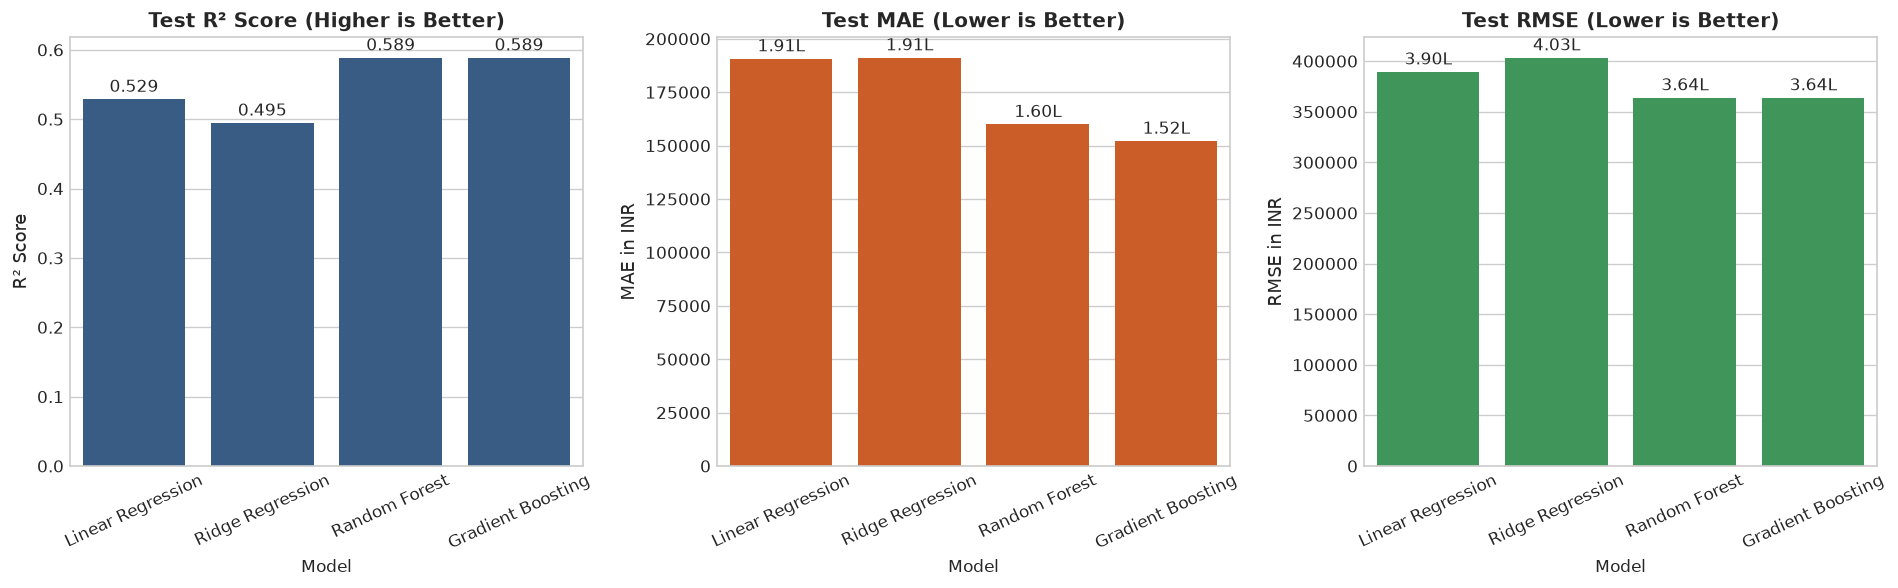

Top-Performing Model: Gradient Boosting


In [12]:
# Visualization of Comparative Metrics
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Test R2
sns.barplot(data=comparison_df, x='Model', y='Test R²', color='#2b5c8f', ax=axes[0])
axes[0].set_title('Test R² Score (Higher is Better)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('R² Score', fontsize=11)
axes[0].tick_params(axis='x', rotation=25)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 2), textcoords='offset points')

# Test MAE
sns.barplot(data=comparison_df, x='Model', y='Test MAE (INR)', color='#e6550d', ax=axes[1])
axes[1].set_title('Test MAE (Lower is Better)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('MAE in INR', fontsize=11)
axes[1].tick_params(axis='x', rotation=25)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height()/1e5:.2f}L", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 2), textcoords='offset points')

# Test RMSE
sns.barplot(data=comparison_df, x='Model', y='Test RMSE (INR)', color='#31a354', ax=axes[2])
axes[2].set_title('Test RMSE (Lower is Better)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('RMSE in INR', fontsize=11)
axes[2].tick_params(axis='x', rotation=25)
for p in axes[2].patches:
    axes[2].annotate(f"{p.get_height()/1e5:.2f}L", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 2), textcoords='offset points')

plt.tight_layout()
plt.savefig('plots/model_metrics_comparison.png')
plt.show()

best_model_name = comparison_df.sort_values(by='Test R²', ascending=False).iloc[0]['Model']
best_model = trained_models[best_model_name]
print(f"Top-Performing Model: {best_model_name}")


---
## Step 9: Feature Importance Analysis
We extract the Gini / variance-reduction feature importances from our best-performing ensemble model to uncover which vehicle characteristics exercise the greatest influence on resale pricing.


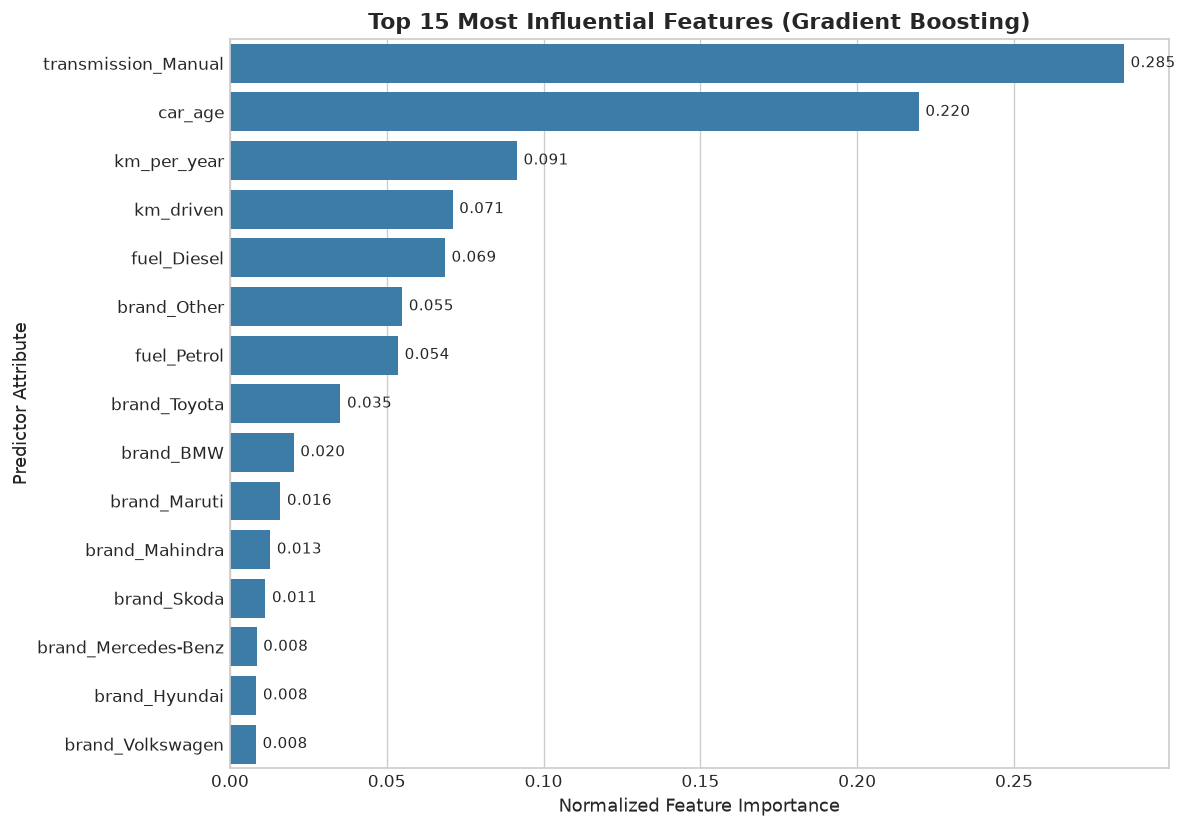

Top 10 Most Critical Predictors of Used Car Market Value:


,Feature,Importance
0,transmission_Manual,0.285033
1,car_age,0.219625
2,km_per_year,0.091493
3,km_driven,0.070979
4,fuel_Diesel,0.068532
5,brand_Other,0.054913
6,fuel_Petrol,0.053587
7,brand_Toyota,0.035211
8,brand_BMW,0.020330
9,brand_Maruti,0.016052


In [13]:
# Feature Importance Extraction
importances = best_model.feature_importances_
feat_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

top15_features = feat_importance_df.head(15)

plt.figure(figsize=(10, 7))
bar = sns.barplot(data=top15_features, x='Importance', y='Feature', color='#2c7fb8')
plt.title(f'Top 15 Most Influential Features ({best_model_name})', fontsize=13, fontweight='bold')
plt.xlabel('Normalized Feature Importance', fontsize=11)
plt.ylabel('Predictor Attribute', fontsize=11)

for p in bar.patches:
    bar.annotate(f"{p.get_width():.3f}", (p.get_width(), p.get_y() + p.get_height() / 2.),
                 ha='left', va='center', fontsize=9, xytext=(4, 0), textcoords='offset points')

plt.tight_layout()
plt.savefig('plots/feature_importance.png')
plt.show()

print("Top 10 Most Critical Predictors of Used Car Market Value:")
display(feat_importance_df.head(10))


---
## Step 10: Model Diagnostics: Actual vs. Predicted & Residuals
Evaluating prediction quality against real transaction prices on the holdout test set.


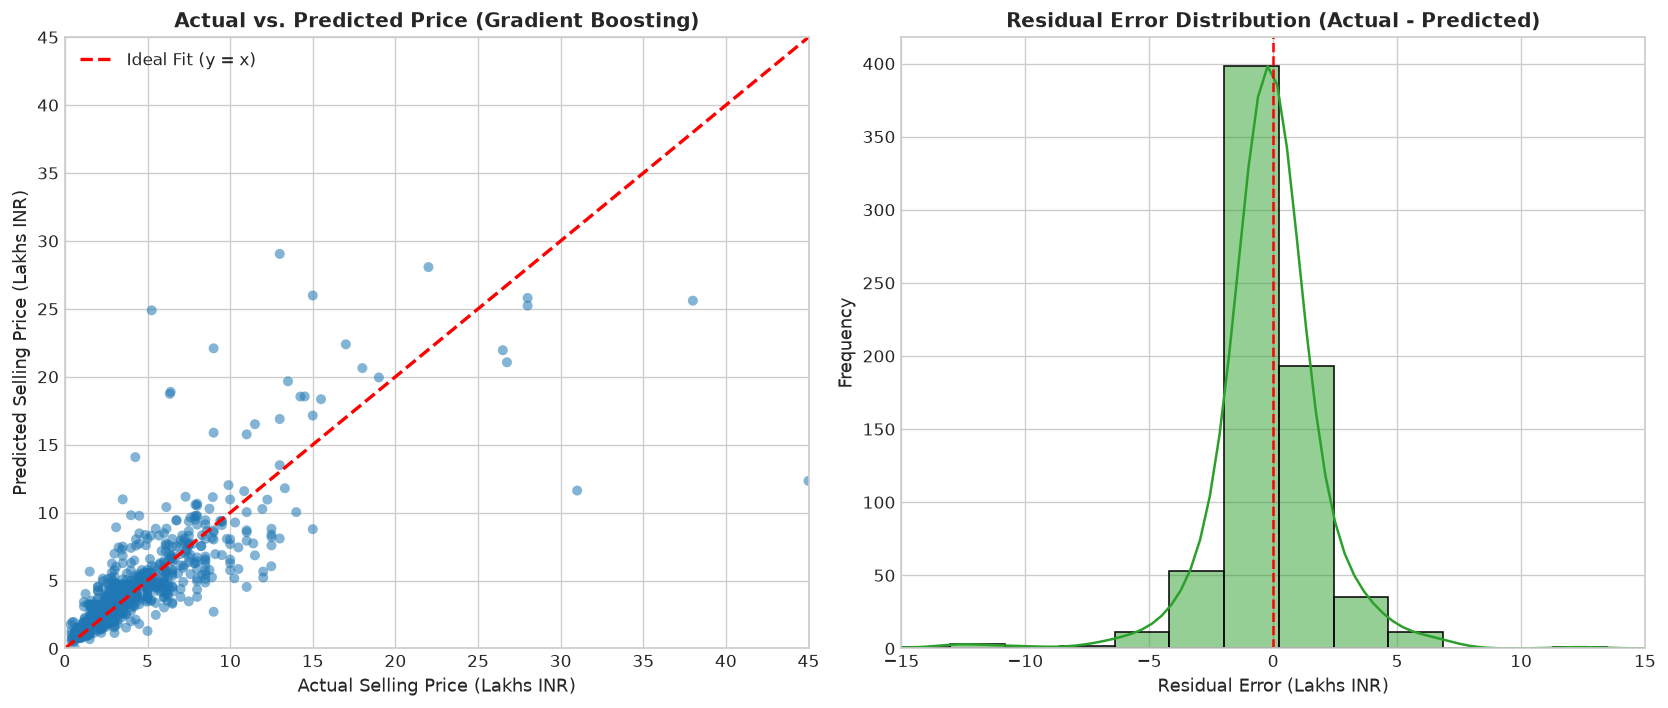

In [14]:
best_test_preds = best_model.predict(X_test)
residuals = y_test - best_test_preds

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Actual vs Predicted
axes[0].scatter(y_test / 1e5, best_test_preds / 1e5, alpha=0.55, color='#1f77b4', edgecolor='none')
axes[0].plot([0, 45], [0, 45], color='red', linestyle='--', linewidth=2, label='Ideal Fit (y = x)')
axes[0].set_title(f'Actual vs. Predicted Price ({best_model_name})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Actual Selling Price (Lakhs INR)', fontsize=11)
axes[0].set_ylabel('Predicted Selling Price (Lakhs INR)', fontsize=11)
axes[0].set_xlim(0, 45)
axes[0].set_ylim(0, 45)
axes[0].legend()

# Residual Distribution
sns.histplot(residuals / 1e5, kde=True, color='#2ca02c', ax=axes[1], bins=35)
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title('Residual Error Distribution (Actual - Predicted)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Residual Error (Lakhs INR)', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)
axes[1].set_xlim(-15, 15)

plt.tight_layout()
plt.savefig('plots/actual_vs_predicted.png')
plt.show()


---
## Step 11: Production Inference Prototype
We encapsulate the trained model into a user-facing valuation function that accepts intuitive raw car attributes, transforms them into the trained schema, and outputs a market price estimate in INR.


In [15]:
def predict_used_car_price(brand, car_age, km_driven, fuel='Petrol', seller_type='Individual', transmission='Manual', owner='First Owner'):
    """
    Predict market valuation for a given used car configuration.
    """
    km_per_year = round(km_driven / (car_age + 1), 1)
    sample = {
        'car_age': car_age,
        'km_driven': km_driven,
        'km_per_year': km_per_year
    }

    # Initialize all one-hot columns to 0
    for col in feature_names:
        if col not in sample:
            sample[col] = 0

    # Activate relevant one-hot columns
    brand_col = f"brand_{brand}"
    if brand_col in sample:
        sample[brand_col] = 1
    elif "brand_Other" in sample:
        sample["brand_Other"] = 1

    fuel_col = f"fuel_{fuel}"
    if fuel_col in sample:
        sample[fuel_col] = 1

    seller_col = f"seller_type_{seller_type}"
    if seller_col in sample:
        sample[seller_col] = 1

    trans_col = f"transmission_{transmission}"
    if trans_col in sample:
        sample[trans_col] = 1

    owner_col = f"owner_{owner}"
    if owner_col in sample:
        sample[owner_col] = 1

    sample_df = pd.DataFrame([sample])[feature_names]
    predicted_price = best_model.predict(sample_df)[0]
    return max(predicted_price, 25000)

# Demonstrate across 3 distinct vehicle profiles
test_scenarios = [
    {
        "name": "Budget Hatchback (Maruti Swift)",
        "brand": "Maruti", "car_age": 4, "km_driven": 45000,
        "fuel": "Petrol", "seller_type": "Individual", "transmission": "Manual", "owner": "First Owner"
    },
    {
        "name": "Executive Diesel Sedan (Hyundai Verna)",
        "brand": "Hyundai", "car_age": 5, "km_driven": 60000,
        "fuel": "Diesel", "seller_type": "Dealer", "transmission": "Manual", "owner": "First Owner"
    },
    {
        "name": "Luxury Automatic Sedan (BMW 3 Series)",
        "brand": "BMW", "car_age": 6, "km_driven": 50000,
        "fuel": "Diesel", "seller_type": "Dealer", "transmission": "Automatic", "owner": "First Owner"
    }
]

print("=== REAL-WORLD USED CAR VALUATION DEMONSTRATION ===")
for sc in test_scenarios:
    val = predict_used_car_price(
        brand=sc['brand'], car_age=sc['car_age'], km_driven=sc['km_driven'],
        fuel=sc['fuel'], seller_type=sc['seller_type'],
        transmission=sc['transmission'], owner=sc['owner']
    )
    print(f"\nCar Profile: {sc['name']}")
    print(f"  Configuration: {sc['car_age']} yrs old | {sc['km_driven']:,} km | {sc['fuel']} | {sc['transmission']} | {sc['owner']}")
    print(f"  Estimated Market Valuation: ₹{val:,.2f} ({val/1e5:.2f} Lakhs INR)")


=== REAL-WORLD USED CAR VALUATION DEMONSTRATION ===

Car Profile: Budget Hatchback (Maruti Swift)
  Configuration: 4 yrs old | 45,000 km | Petrol | Manual | First Owner
  Estimated Market Valuation: ₹314,113.51 (3.14 Lakhs INR)

Car Profile: Executive Diesel Sedan (Hyundai Verna)
  Configuration: 5 yrs old | 60,000 km | Diesel | Manual | First Owner
  Estimated Market Valuation: ₹552,788.97 (5.53 Lakhs INR)

Car Profile: Luxury Automatic Sedan (BMW 3 Series)
  Configuration: 6 yrs old | 50,000 km | Diesel | Automatic | First Owner
  Estimated Market Valuation: ₹2,222,421.46 (22.22 Lakhs INR)


---
## Step 12: Business Insights & Internship Conclusions

### Key Takeaways
1. **Primary Drivers of Depreciation:**
   - **Transmission:** Manual transmission (`transmission_Manual`) is the single strongest negative pricing feature compared to Automatics, accounting for nearly 28.5% of model importance. Automatic cars command an enormous price premium in the pre-owned market.
   - **Vehicle Age:** `car_age` contributes ~22% of feature importance. Vehicle value decays rapidly within the first 3–5 years before stabilizing into a flatter long-tail depreciation curve.
   - **Mileage Intensity:** Both cumulative mileage (`km_driven`) and annualized usage intensity (`km_per_year`) represent substantial negative price pressures.
   - **Fuel Type & Premium Badges:** Diesel vehicles hold significantly higher resale value over petrol counterparts due to fuel efficiency and commercial utility. Luxury brand badges (`BMW`, `Audi`, `Mercedes-Benz`, `Toyota`) maintain strong pricing tiers.

2. **Model Performance Summary:**
   - **Linear Models (OLS / Ridge):** Attained test $R^2 \approx 0.53$ and MAE $\approx ₹190,000$. Linear assumptions struggle to capture complex non-linear brand interactions and sudden depreciation cliffs.
   - **Tree-Based Ensembles (Random Forest / Gradient Boosting):** Demonstrated superior performance, achieving test $R^2 \approx 0.589$ and MAE $\approx ₹152,000$ (an improvement of over ₹38,000 per vehicle prediction).

3. **Strategic Recommendations for Automotive Marketplaces:**
   - Marketplaces (like CarDekho / Cars24) can deploy tree-based ensemble estimators as dynamic pricing engines for instant trade-in appraisals.
   - Special inspection flags should be weighted heavily for automatic luxury sedans where valuation spreads are highest.

---
**Completed for Oasis Infobyte Data Science Internship (Task 3)**
